# 12. Graphs, Networks, Incidence Matrices

## 1. Graphs and Networks

A graph consists of nodes and edges. Nodes represent objects or locations, and edges describe which pairs are connected.

Our example has four nodes and five edges. We assign an arrow to each edge to establish a reference direction. When we later study currents, a positive value will mean flow along that arrow, while a negative value will mean flow in the opposite direction.

The arrows do not prevent current from flowing backward.

We number the edges in the order that we will use throughout the notebook:

| Edge | From node | To node |
|------|-----------|---------|
| 1 | 1 | 2 |
| 2 | 2 | 3 |
| 3 | 1 | 3 |
| 4 | 1 | 4 |
| 5 | 3 | 4 |

These edge numbers identify connections; they are not numerical weights or electrical properties.

In [3]:
import networkx as nx
import matplotlib.pyplot as plt

In [4]:
G = nx.DiGraph()

nodes = [1, 2, 3, 4]

edges = [
    (1, 2),  # Edge 1
    (2, 3),  # Edge 2
    (1, 3),  # Edge 3
    (1, 4),  # Edge 4
    (3, 4),  # Edge 5
]

G.add_nodes_from(nodes)
G.add_edges_from(edges)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Number of nodes: 4
Number of edges: 5


### Visualizing the Connections

We use fixed node positions to make the connections and closed paths easy to follow. These positions only organize the drawing; they do not represent physical distances.

The numbers inside the circles identify nodes. Labels along the arrows identify edges.

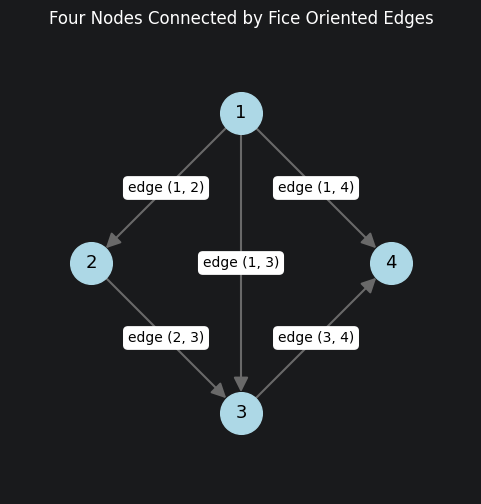

In [5]:
positions = {
    1: (0, 1),
    2: (-1, 0),
    3: (0, -1),
    4: (1, 0)
}

edge_labels = {
    edge: f"edge {edge}" for edge in edges
}

fig, ax = plt.subplots(figsize=(7, 6))

nx.draw_networkx(G, pos=positions, nodelist=nodes, edgelist=edges, ax=ax, node_size=900, node_color='lightblue', edge_color='dimgray', font_size=13, arrows=True, arrowsize=22, width=1.5)
nx.draw_networkx_edge_labels(G, pos=positions, edge_labels=edge_labels, ax=ax, font_size=10, rotate=False)

ax.set_title("Four Nodes Connected by Fice Oriented Edges")
ax.set_aspect('equal')
ax.margins(0.2)
ax.set_axis_off()

plt.show()

### Reading the Graph

Node 1 connects directly to all three other nodes. Nodes 2 and 4 each connect to nodes 1 and 3.

The graph is connected: any node can be reached from any other when we allow traversal in either direction along an edge.

There are also closed paths. For example, we can travel from node 1 to node 2, then to node 3, and return to node 1. The final step runs against the arrow on edge 3, which is allowed when identifying a loop in the underlying graph.

The drawing makes these connections visible. Next, we will encode the same information in a matrix.

## 2. The Incidence Matrix

The graph shows which nodes are connected. We now encode those connections in a matrix so we can work with them computationally.

Our incidence matrix A has:

- One row for each edge.
- One column for each node.

For an edge directed from node a to node b, its row contains:

- -1 in the column for node a, where the edge starts.
- +1 in the column for node b, where the edge ends.
- 0 in every other column.

For example, edge 1 goes from node 1 to node 2, so its row is:

    [-1, 1, 0, 0]

Each row records one connection. The signs record its reference direction.

In [6]:
import numpy as np
from sympy import Matrix

A = np.zeros((len(edges), len(nodes)))

for row, (start, end) in enumerate(edges):
    start_column = nodes.index(start)
    end_column = nodes.index(end)

    A[row, start_column] = -1
    A[row, end_column] = 1

display(Matrix(A))
print(f"Shape (edges, nodes): {A.shape}")

Matrix([
[-1.0,  1.0,  0.0, 0.0],
[ 0.0, -1.0,  1.0, 0.0],
[-1.0,  0.0,  1.0, 0.0],
[-1.0,  0.0,  0.0, 1.0],
[ 0.0,  0.0, -1.0, 1.0]])

Shape (edges, nodes): (5, 4)


### Reading the Matrix

The resulting matrix has five rows and four columns, matching our five edges and four nodes.

Reading across a row identifies an edge's two endpoints. Reading down a column identifies all edges touching a node:

- -1 means the edge leaves that node.
- +1 means the edge enters that node.
- 0 means the edge does not touch that node.

Every row contains exactly two nonzero entries, and its entries sum to zero.

### Checking the Structure

We can check that our construction follows the incidence rule by counting the nonzero entries in each row and calculating each row's sum.

For a larger network, each edge would still involve only two nodes. Most matrix entries would therefore be zero—a structure called sparsity.

In [7]:
nonezero_per_row = np.count_nonzero(A, axis=1)
row_sums = A.sum(axis=1)
print(f"Nonzero entries per row: {nonezero_per_row}")
print(f"Row sums: {row_sums}")

Nonzero entries per row: [2 2 2 2 2]
Row sums: [0. 0. 0. 0. 0.]


Each row has exactly two nonzero entries: one -1 and one +1. Consequently, every row sums to zero.

These checks confirm that every edge has been assigned a starting node and an ending node.

### Conclusion

The incidence matrix translates connections and orientations into numbers. Each edge becomes a row containing a starting-node marker and an ending-node marker.

We can now investigate how features of the graph, such as closed paths, appear as relationships between matrix rows.

## 3. Loops and Row Dependence

What happens when a group of edges forms a closed path?

Consider the path from node 1 to node 2, then to node 3, and back to node 1. It uses edges 1, 2, and 3.

We follow the arrows on edges 1 and 2, but travel against the arrow on edge 3. This gives the signed combination:

    edge 1 + edge 2 - edge 3

Let us highlight this loop and investigate the same combination of matrix rows.

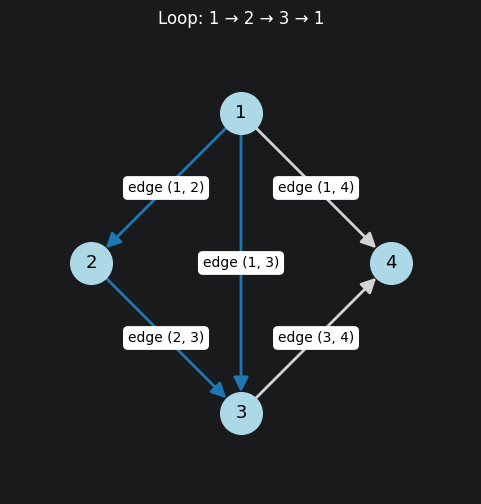

In [8]:
loop_edges = [(1, 2), (2, 3), (1, 3)]
edge_colors = ["tab:blue" if edge in loop_edges else "lightgray" for edge in edges]

fig, ax = plt.subplots(figsize=(7, 6))

nx.draw_networkx(
    G,
    pos=positions,
    nodelist=nodes,
    edgelist=edges,
    ax=ax,
    node_size=900,
    node_color="lightblue",
    edge_color=edge_colors,
    font_size=13,
    arrows=True,
    arrowsize=22,
    width=2,
)

nx.draw_networkx_edge_labels(
    G,
    pos=positions,
    edge_labels=edge_labels,
    ax=ax,
    font_size=10,
    rotate=False,
)

ax.set_title("Loop: 1 → 2 → 3 → 1")
ax.set_aspect("equal")
ax.margins(0.2)
ax.set_axis_off()

plt.show()

### Following the Loop in the Matrix

Each row describes a change between nodes. Adding the rows for edges 1 and 2 combines the steps:

    node 1 → node 2 → node 3

At the intermediate node, the +1 from arriving and the -1 from leaving cancel.

Does this combined row match the row for the direct connection from node 1 to node 3?

In [9]:
row1 = A[0]
row2 = A[1]
row3 = A[2]

print("Row 1:", row1)
print("Row 2:", row2)

print("\nRow 1 + Row 2:", row1 + row2)
print("Row 3:        ", row3)

loop_sum = row1 + row2 - row3

print("\nRow 1 + Row 2 - Row 3:", loop_sum)
print("Is the result zero?", np.all(loop_sum == 0))

Row 1: [-1.  1.  0.  0.]
Row 2: [ 0. -1.  1.  0.]

Row 1 + Row 2: [-1.  0.  1.  0.]
Row 3:         [-1.  0.  1.  0.]

Row 1 + Row 2 - Row 3: [0. 0. 0. 0.]
Is the result zero? True


### Interpreting the Result

The first two rows add to the third:

    row 1 + row 2 = row 3

Equivalently:

    row 1 + row 2 - row 3 = 0

This is a linear dependence: a combination of rows equals the zero vector even though its coefficients are not all zero.

The cancellation reflects the closed path. Every node on the loop is entered and left, so the signed contributions cancel.

### Conclusion

A loop in the graph produces a dependence among its incidence-matrix rows. The third edge closes this loop without adding an independent row direction.

We will later use these signed loop combinations to describe conserved flows.

## 4. Node Potentials and Edge Differences

### 4.1 What Is a Node Potential?

Imagine measuring the height of several locations. To report their heights, we first choose a reference level. However, the height difference between two locations stays the same if we change that reference.

Electrical potential works similarly: each node has a potential measured relative to a chosen reference. Potential is measured in volts (V), which represent electrical potential energy per unit charge.

For an electrical connection, the important quantity is the potential difference between its endpoints.

We will assign illustrative potentials to our four nodes and investigate how the incidence matrix calculates these differences. These values are chosen for demonstration; we have not solved an electrical circuit yet.

In [10]:
x = np.array([6, 4, 1, 0])
for node, potential in zip(nodes, x):
    print(f"Node {node} has potential {potential} V")

Node 1 has potential 6 V
Node 2 has potential 4 V
Node 3 has potential 1 V
Node 4 has potential 0 V


### 4.2 From Two Node Potentials to One Edge Difference

Edge 1 points from node 1 to node 2.

We define the signed difference along an arrow as:

    destination potential - starting potential

For edge 1, this gives:

    e1 = x2 - x1

This convention tells us how the potential changes as we move along the arrow. A negative result means that we arrive at a lower potential.

In [11]:
start, end = edges[0]

start_potential = x[nodes.index(start)]
end_potential = x[nodes.index(end)]

difference = end_potential - start_potential

print(f"Edge 1: node {start} → node {end}")
print(f"Starting potential: {start_potential} V")
print(f"Destination potential: {end_potential} V")
print(f"Potential difference: {difference} V")

Edge 1: node 1 → node 2
Starting potential: 6 V
Destination potential: 4 V
Potential difference: -2 V


The result is -2 V: moving from node 1 to node 2 takes us from 6 V to 4 V.

If we traversed the same connection backward, the difference would be +2 V. The endpoint potentials would remain unchanged; only the direction used to measure their difference would change.

### 4.3 How Does a Matrix Row Calculate This?

The first row of A represents edge 1:

    [-1, 1, 0, 0]

Taking its dot product with the potential vector gives:

    -1*x1 + 1*x2 + 0*x3 + 0*x4 = x2 - x1

The -1 subtracts the starting potential. The +1 adds the destination potential. The zeros exclude nodes that are not endpoints of this edge.

This explains why the incidence matrix uses these particular entries.

In [12]:
edge1_row = A[0]

print("Row for edge 1:", edge1_row)
print("Node potentials:", x)

contributions = edge1_row * x

print("Contribution from each node:", contributions)
print("Sum of contributions:", contributions.sum(), "V")
print("Same calculation using a dot product:", edge1_row @ x, "V")

Row for edge 1: [-1.  1.  0.  0.]
Node potentials: [6 4 1 0]
Contribution from each node: [-6.  4.  0.  0.]
Sum of contributions: -2.0 V
Same calculation using a dot product: -2.0 V


### 4.4 Calculating All Edge Differences Together

Every row performs the same operation for a different edge. Multiplying the entire matrix by x performs all five calculations together:

    e = Ax

The input x contains one potential per node. The output e contains one signed difference per edge.

The order of the output follows the row order of A, which is the edge order we established earlier.

In [13]:
e = A @ x

print("A shape:", A.shape)
print("x shape:", x.shape)
print("e shape:", e.shape)

print("\nEdge differences:")
for i, (start, end) in enumerate(edges, start=1):
    print(
        f"e{i}: node {start} → node {end}, "
        f"{x[nodes.index(end)]} - {x[nodes.index(start)]} "
        f"= {e[i - 1]} V"
    )

A shape: (5, 4)
x shape: (4,)
e shape: (5,)

Edge differences:
e1: node 1 → node 2, 4 - 6 = -2.0 V
e2: node 2 → node 3, 1 - 4 = -3.0 V
e3: node 1 → node 3, 1 - 6 = -5.0 V
e4: node 1 → node 4, 0 - 6 = -6.0 V
e5: node 3 → node 4, 0 - 1 = -1.0 V


### 4.5 Seeing Potentials and Differences on the Graph

The labels inside the nodes show their potentials. The labels along the edges show the differences calculated by A.

For any arrow, subtract the value at its starting node from the value at its destination. The result should match the edge label.

These are potential differences. Determining the resulting currents will also require information about the electrical properties of the edges.

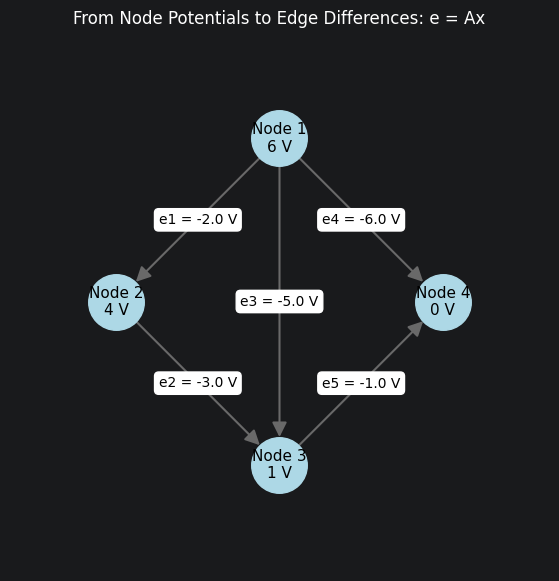

In [14]:
potential_labels = {node: f"Node {node}\n{potential} V" for node, potential in zip(nodes, x)}
difference_labels = {edge: f"e{i} = {difference} V" for i, (edge, difference) in enumerate(zip(edges, e), start=1)}

fig, ax = plt.subplots(figsize=(8, 7))

nx.draw_networkx(
    G,
    pos=positions,
    nodelist=nodes,
    edgelist=edges,
    labels=potential_labels,
    ax=ax,
    node_size=1600,
    node_color="lightblue",
    edge_color="dimgray",
    font_size=11,
    arrows=True,
    arrowsize=22,
    width=1.5,
)

nx.draw_networkx_edge_labels(
    G,
    pos=positions,
    edge_labels=difference_labels,
    ax=ax,
    font_size=10,
    rotate=False,
)

ax.set_title("From Node Potentials to Edge Differences: e = Ax")
ax.set_aspect("equal")
ax.margins(0.25)
ax.set_axis_off()

plt.show()

### Conclusion

The incidence matrix contains the instructions for comparing connected nodes:

- Each row selects two endpoints.
- Its signs specify which potential to subtract and which to add.
- Multiplication by x calculates every edge difference at once.

Thus, e = Ax connects the graph's structure to values assigned to its nodes.

Our next question is: which assignments of node potentials make all these differences zero?

## 5. Null Space, Grounding, and Rank

### 5.1 Which Potentials Produce Zero Differences?

The null space of A consists of all potential vectors satisfying:

    Ax = 0

First, multiply A by a symbolic vector of node potentials to see which differences must equal zero.

In [15]:
from sympy import symbols

x1, x2, x3, x4 = symbols("x1 x2 x3 x4")

A_exact = Matrix(A)
x_symbolic = Matrix([x1, x2, x3, x4])

differences = A_exact * x_symbolic

for edge_number, expression in enumerate(differences, start=1):
    print(f"Edge {edge_number}: {expression} = 0")

Edge 1: -1.0*x1 + 1.0*x2 = 0
Edge 2: -1.0*x2 + 1.0*x3 = 0
Edge 3: -1.0*x1 + 1.0*x3 = 0
Edge 4: -1.0*x1 + 1.0*x4 = 0
Edge 5: -1.0*x3 + 1.0*x4 = 0


We can solve these equations by following the connections:

1. Edge 1 gives x2 - x1 = 0, so x2 = x1.
2. Edge 2 gives x3 - x2 = 0, so x3 = x2 = x1.
3. Edge 3 gives x3 - x1 = 0, which is already satisfied.
4. Edge 4 gives x4 - x1 = 0, so x4 = x1.
5. Edge 5 gives x4 - x3 = 0, which is also already satisfied.

Every potential must therefore equal the same freely chosen value.

Calling that value c, we obtain:

    x = [c, c, c, c]
      = c * [1, 1, 1, 1]

There is exactly one free parameter. We can now construct the basis vector ourselves and verify it by multiplication.

In [16]:
basis_vector = Matrix([1, 1, 1, 1])
null_basis = [basis_vector]

print("Basis vector:")
display(basis_vector)

print("A multiplied by the basis vector:")
display(A_exact * basis_vector)

Basis vector:


Matrix([
[1],
[1],
[1],
[1]])

A multiplied by the basis vector:


Matrix([
[0],
[0],
[0],
[0],
[0]])

### 5.2 Interpreting the Null-Space Basis

The calculation gives one basis vector:

    [1, 1, 1, 1]

Every null-space vector is a scalar multiple of it:

    x = c * [1, 1, 1, 1]

Thus, all four nodes can share any common potential and still have zero difference across every edge.

There is one freely selectable number, c. Therefore, the null space has dimension 1.

We can verify this using several common potential levels.

In [17]:
for common_potential in [-3, 0, 7]:
    constant_x = common_potential * np.ones(len(nodes), dtype=int)

    print("Node potentials:", constant_x)
    print("Edge differences:", A @ constant_x)
    print()

Node potentials: [-3 -3 -3 -3]
Edge differences: [0. 0. 0. 0. 0.]

Node potentials: [0 0 0 0]
Edge differences: [0. 0. 0. 0. 0.]

Node potentials: [7 7 7 7]
Edge differences: [0. 0. 0. 0. 0.]



### 5.3 Why Edge Differences Cannot Determine Absolute Potentials

This freedom also applies when the edge differences are nonzero.

Adding the same constant to every node potential leaves every difference unchanged:

    (xb + c) - (xa + c) = xb - xa

Consequently, knowing Ax cannot tell us which common reference level was used for x.

Let us shift all our earlier potentials by the same amount and compare the results.

In [18]:
offset = 10

x_shifted = x + offset

print("Original potentials:", x)
print("Shifted potentials: ", x_shifted)

print("\nOriginal differences:", A @ x)
print("Shifted differences: ", A @ x_shifted)

print(
    "\nAre the differences unchanged?",
    np.allclose(A @ x, A @ x_shifted),
)

Original potentials: [6 4 1 0]
Shifted potentials:  [16 14 11 10]

Original differences: [-2. -3. -5. -6. -1.]
Shifted differences:  [-2. -3. -5. -6. -1.]

Are the differences unchanged? True


### 5.4 Grounding a Node

To remove this ambiguity, we choose one node as the zero-potential reference. This is called grounding the node.

To ground node 4, subtract its potential from every node:

    grounded potential at node i = xi - x4

Node 4 then has potential zero, while every edge difference stays unchanged.

Our original example already had x4 = 0. We will instead ground the shifted potentials to show how the reference is removed.

In [19]:
ground_node = 4
ground_column = nodes.index(ground_node)

x_grounded = x_shifted - x_shifted[ground_column]

print("Shifted potentials: ", x_shifted)
print("Grounded potentials:", x_grounded)
print(f"Potential at node {ground_node}:", x_grounded[ground_column], "V")

print(
    "\nAre the edge differences preserved?",
    np.allclose(A @ x_grounded, A @ x_shifted),
)

Shifted potentials:  [16 14 11 10]
Grounded potentials: [6 4 1 0]
Potential at node 4: 0 V

Are the edge differences preserved? True


Grounding fixes the common reference level. It does not supply the potential differences themselves.

If compatible edge differences are known, grounding one node makes the corresponding node potentials unique for this connected graph.

### 5.5 Connecting Null Space to Rank

The rank of A is the dimension of its column space: the number of independent output directions it can produce.

The rank-nullity relationship states:

    number of columns = rank + null-space dimension

Our matrix has four columns. By solving Ax = 0, we found that every solution depends on exactly one free parameter, so the null-space dimension is 1.

We can therefore determine the rank:

    rank = number of columns - null-space dimension

In [20]:
number_of_columns = A.shape[1]

nullity = 1

rank = number_of_columns - nullity

print("Number of columns:", number_of_columns)
print("Null-space dimension:", nullity)
print("Rank from rank-nullity:", rank)

Number of columns: 4
Null-space dimension: 1
Rank from rank-nullity: 3


The rank is 3.

Although x has four coordinates, changing all four potentials by the same amount leaves Ax unchanged. This common shift accounts for the one-dimensional null space.

The remaining three independent potential coordinates determine the edge differences once a reference node is grounded.

### Conclusion

The calculation gives rank 3 and null-space dimension 1:

    4 = 3 + 1

The network has four node potentials, but their common reference level does not affect edge differences. Grounding removes that one degree of freedom.

For this connected graph:

- N(A) consists of constant potential vectors.
- Grounding one node fixes the potential reference.
- Three independent potential coordinates remain to determine the edge differences.

## 6. The Column Space: Which Edge Differences Are Possible?

### 6.1 Five Differences, but Only Three Independent Directions

Multiplying A by node potentials produces five edge differences:

    e = Ax

The column space of A, written C(A), is the set of all outputs that this multiplication can produce.

Equivalently, Ax combines the columns of A using the node potentials as coefficients:

    Ax = x1*column1 + x2*column2 + x3*column3 + x4*column4

But can we choose all five edge differences independently?

We found that A has rank 3, so its column space has dimension 3. Therefore, its five output entries must satisfy constraints. We will discover those constraints by following paths through the graph.

### 6.2 Comparing Two Paths Between the Same Nodes

There are two ways to travel from node 1 to node 3:

- Follow edge 1, then edge 2.
- Follow edge 3 directly.

Both paths start and end at the same potentials, so their total potential changes must agree:

    e1 + e2 = e3

The intermediate potential cancels:

    (x2 - x1) + (x3 - x2) = x3 - x1

Let us check this using the edge differences we calculated earlier.

In [21]:
e = A @ x

print("Via node 2:", e[0] + e[1], "V")
print("Directly:  ", e[2], "V")

first_loop_sum = e[0] + e[1] - e[2]

print("Signed change around the loop:", first_loop_sum, "V")

Via node 2: -5.0 V
Directly:   -5.0 V
Signed change around the loop: 0.0 V


The signed sum around the closed path is zero:

    e1 + e2 - e3 = 0

We return to the starting node, so the total change in potential must vanish.

For differences derived from node potentials, this is Kirchhoff's voltage law: signed potential changes around a closed path sum to zero.

### 6.3 A Second Constraint

We can also reach node 4 from node 1 in two ways:

- Follow edge 3, then edge 5.
- Follow edge 4 directly.

Therefore, compatible differences must also satisfy:

    e3 + e5 = e4

Or, as a closed-path sum:

    e3 + e5 - e4 = 0

In [22]:
print("Via node 3:", e[2] + e[4], "V")
print("Directly:  ", e[3], "V")

second_loop_sum = e[2] + e[4] - e[3]

print("Signed change around the second loop:", second_loop_sum, "V")

Via node 3: -6.0 V
Directly:   -6.0 V
Signed change around the second loop: 0.0 V


### 6.4 Testing an Incompatible Assignment

Suppose we change the difference assigned to edge 3 while leaving the other differences unchanged.

Can any assignment of node potentials produce this new vector?

If two paths between the same nodes imply different potential changes, no consistent node potentials can exist.

In [23]:
e_incompatible = e.copy()
e_incompatible[2] += 1

for name, candidate in [
    ("Original differences", e),
    ("Modified differences", e_incompatible),
]:
    loop1 = candidate[0] + candidate[1] - candidate[2]
    loop2 = candidate[2] + candidate[4] - candidate[3]

    print(name, ":", candidate)
    print("First loop sum:", loop1, "V")
    print("Second loop sum:", loop2, "V")
    print()

Original differences : [-2. -3. -5. -6. -1.]
First loop sum: 0.0 V
Second loop sum: 0.0 V

Modified differences : [-2. -3. -4. -6. -1.]
First loop sum: -1.0 V
Second loop sum: 1.0 V



The modified vector fails the loop conditions. It cannot equal Ax for any node-potential vector x, so it lies outside C(A).

### 6.5 Why These Conditions Are Also Sufficient

The two loop conditions are necessary. To show they completely describe C(A), we can reconstruct node potentials from any differences satisfying them.

Ground node 1 by choosing x1 = 0. Then use edges 1, 2, and 4:

    x2 = e1
    x3 = e1 + e2
    x4 = e4

The first loop condition ensures that edge 3 has the required difference. The second ensures the same for edge 5.

Let us reconstruct the potentials and verify all five differences.

In [24]:
x_reconstructed = np.array([
    0,
    e[0],
    e[0] + e[1],
    e[3],
])

print("Reconstructed potentials:", x_reconstructed)
print("Resulting differences:   ", A @ x_reconstructed)
print("Required differences:    ", e)

print(
    "\nDo all five differences match?",
    np.allclose(A @ x_reconstructed, e),
)

Reconstructed potentials: [ 0. -2. -5. -6.]
Resulting differences:    [-2. -3. -5. -6. -1.]
Required differences:     [-2. -3. -5. -6. -1.]

Do all five differences match? True


### Conclusion

The column space contains exactly the edge-difference vectors that satisfy:

    e1 + e2 - e3 = 0
    e3 + e5 - e4 = 0

These two independent constraints leave three freely selectable edge differences, matching rank 3.

Node potentials produce consistent differences along every path. The loop conditions express that consistency directly in the graph.

## 7. Currents and Kirchhoff’s Current Law

### 7.1 From Potential Differences to Flows

We now consider a different quantity on each edge: electrical current.

Current measures the rate at which electric charge flows, in amperes (A). We collect the five edge currents into a vector:

    y = [y1, y2, y3, y4, y5]

Each current uses the edge's arrow as its reference direction:

- A positive value means flow along the arrow.
- A negative value means flow against the arrow.
- Zero means no current on that edge.

For now, we will investigate conservation of current. We have not yet used electrical properties to determine which currents the network would produce.

### 7.2 Balancing Current at One Node

In a steady state, charge does not accumulate at a node. If no external current enters or leaves there, total incoming current must equal total outgoing current.

This is Kirchhoff's current law.

At node 2:

- Edge 1 enters the node.
- Edge 2 leaves the node.

Its balance equation is therefore:

    y1 - y2 = 0

Let us compare two assignments of these currents.

In [25]:
for incoming, outgoing in [(2, 2), (2, 1)]:
    balance = incoming - outgoing

    print(f"Incoming: {incoming} A; outgoing: {outgoing} A")
    print(f"Incoming minus outgoing: {balance} A")
    print("Balanced?", balance == 0)
    print()

Incoming: 2 A; outgoing: 2 A
Incoming minus outgoing: 0 A
Balanced? True

Incoming: 2 A; outgoing: 1 A
Incoming minus outgoing: 1 A
Balanced? False



A nonzero balance indicates that the listed edge currents do not conserve charge at that node without an external current or charge accumulation.

We will use the steady-state model and initially assume no external currents.

### 7.3 Assembling All Node Balances

Recall how A records each edge:

- -1 at its starting node.
- +1 at its destination node.

After transposing A, each row corresponds to a node and each column to an edge.

Multiplying A.T by y therefore adds incoming currents and subtracts outgoing currents at every node:

    A.T @ y = node balances

For our graph, the equations are:

    Node 1: -y1 - y3 - y4 = 0
    Node 2:  y1 - y2 = 0
    Node 3:  y2 + y3 - y5 = 0
    Node 4:  y4 + y5 = 0

Together, these become:

    A.T @ y = 0

In [26]:
AT = A.T

print("Transpose shape (nodes, edges):", AT.shape)
display(Matrix(AT))

Transpose shape (nodes, edges): (4, 5)


Matrix([
[-1.0,  0.0, -1.0, -1.0,  0.0],
[ 1.0, -1.0,  0.0,  0.0,  0.0],
[ 0.0,  1.0,  1.0,  0.0, -1.0],
[ 0.0,  0.0,  0.0,  1.0,  1.0]])

### 7.4 Testing a Conserved Flow

Consider one ampere circulating along the path:

    node 1 → node 2 → node 3 → node 1

The final step runs against the arrow on edge 3, so its current must be negative.

We will assign these currents and calculate the balance at every node.

In [27]:
# Edge order: 1→2, 2→3, 1→3, 1→4, 3→4
y = np.array([1, 1, -1, 0, 0])

node_balances = AT @ y

for i, ((start, end), current) in enumerate(zip(edges, y), start=1):
    print(f"Edge {i} ({start} → {end}): {current} A")

print("\nNode balances:")
for node, balance in zip(nodes, node_balances):
    print(f"Node {node}: {balance} A")

print("\nConserves current at every node?", np.all(node_balances == 0))

Edge 1 (1 → 2): 1 A
Edge 2 (2 → 3): 1 A
Edge 3 (1 → 3): -1 A
Edge 4 (1 → 4): 0 A
Edge 5 (3 → 4): 0 A

Node balances:
Node 1: 0.0 A
Node 2: 0.0 A
Node 3: 0.0 A
Node 4: 0.0 A

Conserves current at every node? True


Every node has zero balance. At node 1, for example, one ampere leaves through edge 1 and one ampere returns through edge 3.

This vector satisfies current conservation. Whether such a nonzero circulation can physically occur also depends on the circuit's components and sources.

### 7.5 Detecting an Imbalance

Now increase the current on edge 1 without changing the other currents.

This adds flow from node 1 to node 2. We should therefore see a deficit at node 1 and a surplus at node 2.

In [28]:
y_unbalanced = y.copy()
y_unbalanced[0] += 1

unbalanced_node_balances = AT @ y_unbalanced

for node, balance in zip(nodes, unbalanced_node_balances):
    print(f"Node {node}: {balance} A")

print(
    "\nConserves current at every node?",
    np.all(unbalanced_node_balances == 0),
)

Node 1: -1.0 A
Node 2: 1.0 A
Node 3: 0.0 A
Node 4: 0.0 A

Conserves current at every node? False


### Conclusion

The incidence matrix and its transpose perform two different network operations:

    Ax      → differences between node potentials
    A.T @ y → current balances at nodes

The solutions of A.T @ y = 0 form the left null space of A, written N(A.T).

In this network, that space consists of all edge-flow assignments that conserve current at every node without external currents. Next, we will construct a basis for it using independent loops.

## 8. A Basis of Loop Flows

### 8.1 How Many Independent Conserved Flows Are There?

We want to describe every current vector satisfying:

    A.T @ y = 0

There are five edge currents, so y has five coordinates. The transpose has the same rank as A.

Using rank-nullity:

    dim N(A.T) = number of edges - rank

Let us calculate how many independent flow directions we need.

In [29]:
number_of_edges = len(edges)
left_nullity = number_of_edges - rank

print("Number of edge currents:", number_of_edges)
print("Rank:", rank)
print("Dimension of N(A.T):", left_nullity)

Number of edge currents: 5
Rank: 3
Dimension of N(A.T): 2


The dimension is 2. Therefore, a basis must contain two independent conserved-flow vectors.

We will construct them from the two inner loops rather than use a null-space method.

### 8.2 Constructing Two Loop Flows

For the first loop, follow:

    1 → 2 → 3 → 1

This uses edges 1 and 2 along their arrows, then edge 3 against its arrow.

For the second loop, follow:

    1 → 3 → 4 → 1

This uses edges 3 and 5 along their arrows, then edge 4 against its arrow.

Assign one unit of flow around each loop and zero on unused edges.

In [30]:
loop1 = np.array([1, 1, -1, 0, 0])
loop2 = np.array([0, 0, 1, -1, 1])

for name, flow in [("First loop", loop1), ("Second loop", loop2)]:
    print(name, ":", flow)
    print("Node balances:", AT @ flow)
    print()

First loop : [ 1  1 -1  0  0]
Node balances: [0. 0. 0. 0.]

Second loop : [ 0  0  1 -1  1]
Node balances: [0. 0. 0. 0.]



Both vectors conserve current at every node.

They are also independent. To see why, suppose:

a*loop1 + b*loop2 = 0

Only loop1 uses edge 1, so the first coordinate forces a = 0. Only loop2 uses edge 4, so the fourth coordinate then forces b = 0.

We have two independent vectors in a two-dimensional space. They therefore form a basis for N(A.T).

Every conserved flow can be written as:

y = a*loop1 + b*loop2

In [32]:
a = 2
b = 3

combined_flow = a * loop1 + b * loop2

print("Combined edge currents:", combined_flow)
print("Node balances:", AT @ combined_flow)

Combined edge currents: [ 2  2  1 -3  3]
Node balances: [0. 0. 0. 0.]


### 8.3 Combining the Inner Loops

What happens if we add one unit of each loop flow?

On their shared edge, edge 3, the first loop flows against the reference arrow while the second flows along it. Those contributions cancel.

The remaining flow follows the outer path:

    1 → 2 → 3 → 4 → 1

In [33]:
outer_loop = loop1 + loop2

print("First loop: ", loop1)
print("Second loop:", loop2)
print("Their sum:  ", outer_loop)
print("Node balances:", AT @ outer_loop)

First loop:  [ 1  1 -1  0  0]
Second loop: [ 0  0  1 -1  1]
Their sum:   [ 1  1  0 -1  1]
Node balances: [0. 0. 0. 0.]


### 8.4 Visualizing the Flow Directions

The following plots show actual flow directions for these examples. A negative component reverses the corresponding reference arrow, and edges with zero flow are shown faintly without arrows.

This lets us see how the shared-edge flows cancel when the two inner loops are added.

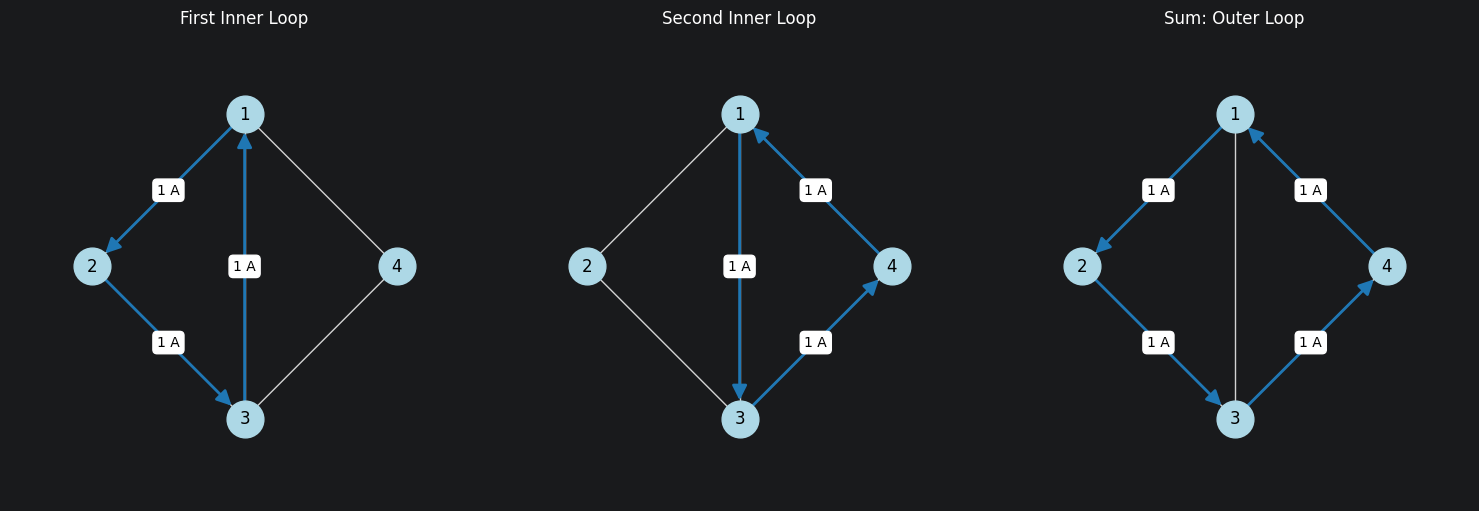

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

examples = [
    ("First Inner Loop", loop1),
    ("Second Inner Loop", loop2),
    ("Sum: Outer Loop", outer_loop),
]

for ax, (title, flow) in zip(axes, examples):
    nx.draw_networkx(
        G,
        pos=positions,
        ax=ax,
        node_size=700,
        node_color="lightblue",
        edge_color="lightgray",
        arrows=False,
        font_size=12,
    )

    active_edges = []
    flow_labels = {}

    for (start, end), current in zip(edges, flow):
        if current == 0:
            continue

        actual_edge = (
            (start, end) if current > 0 else (end, start)
        )

        active_edges.append(actual_edge)
        flow_labels[actual_edge] = f"{abs(current)} A"

    flow_graph = nx.DiGraph()
    flow_graph.add_nodes_from(nodes)
    flow_graph.add_edges_from(active_edges)

    nx.draw_networkx_edges(
        flow_graph,
        pos=positions,
        edgelist=active_edges,
        ax=ax,
        node_size=700,
        edge_color="tab:blue",
        arrows=True,
        arrowsize=22,
        width=2,
    )

    nx.draw_networkx_edge_labels(
        flow_graph,
        pos=positions,
        edge_labels=flow_labels,
        ax=ax,
        rotate=False,
        font_size=10,
    )

    ax.set_title(title)
    ax.set_aspect("equal")
    ax.margins(0.2)
    ax.set_axis_off()

plt.tight_layout()
plt.show()

### Conclusion

The two inner loops form a basis for the conserved-flow space N(A.T).

The outer loop is another conserved flow, but it adds no independent direction: it is the sum of the two basis vectors.

Thus, this graph has three simple cycles but only two independent cycles. The dimension of the left null space counts independent cycles.

## 9. Trees and Independent Edges

### 9.1 Connecting All Nodes Without Closing a Loop

We have seen that a cycle creates a dependence among incidence-matrix rows.

What if we select enough edges to connect every node, while avoiding cycles?

Such a selection is called a spanning tree:

- It includes every node of the original graph.
- It is connected.
- It contains no cycles.

Let us examine edges 1, 2, and 4.

In [35]:
tree_indices = [0, 1, 3]
tree_edges = [edges[i] for i in tree_indices]

tree_graph = nx.Graph()
tree_graph.add_nodes_from(nodes)
tree_graph.add_edges_from(tree_edges)

print("Selected edges:")
for i in tree_indices:
    print(f"Edge {i + 1}: {edges[i][0]} → {edges[i][1]}")

Selected edges:
Edge 1: 1 → 2
Edge 2: 2 → 3
Edge 4: 1 → 4


### 9.2 Seeing the Spanning Tree

Edges 1 and 2 connect nodes 1, 2, and 3. Edge 4 connects node 4 to node 1.

All four nodes are connected, and there is exactly one simple path between any pair of nodes. No edge closes a cycle.

We use the underlying undirected connections to identify the tree; the arrows remain reference directions.

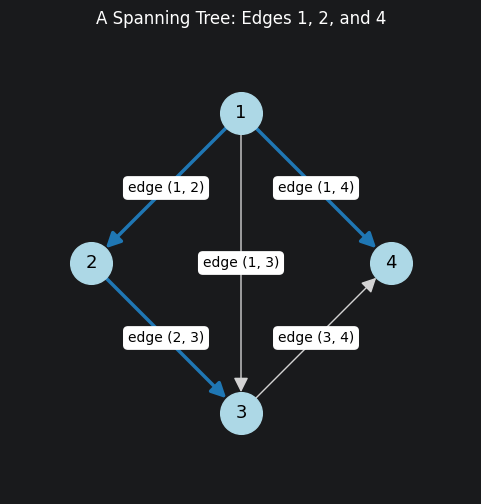

In [36]:
tree_colors = [
    "tab:blue" if i in tree_indices else "lightgray"
    for i in range(len(edges))
]

tree_widths = [
    2.5 if i in tree_indices else 1
    for i in range(len(edges))
]

fig, ax = plt.subplots(figsize=(7, 6))

nx.draw_networkx(
    G,
    pos=positions,
    nodelist=nodes,
    edgelist=edges,
    ax=ax,
    node_size=900,
    node_color="lightblue",
    edge_color=tree_colors,
    width=tree_widths,
    arrows=True,
    arrowsize=22,
    font_size=13,
)

nx.draw_networkx_edge_labels(
    G,
    pos=positions,
    edge_labels=edge_labels,
    ax=ax,
    rotate=False,
    font_size=10,
)

ax.set_title("A Spanning Tree: Edges 1, 2, and 4")
ax.set_aspect("equal")
ax.margins(0.2)
ax.set_axis_off()

plt.show()

### 9.3 Why Are These Edges Independent?

Each selected edge corresponds to a row of A. To test independence, suppose:

    a*row1 + b*row2 + c*row4 = 0

Consider the node coordinates:

- Only row4 contributes to node 4, so c must be zero.
- Only row2 contributes to node 3, so b must be zero.
- With b = 0, the node 2 coordinate forces a to be zero.

Only zero coefficients produce the zero vector. Therefore, the three rows are independent.

Let us display the selected rows and their symbolic combination.

In [38]:
tree_rows = A[tree_indices, :]

print("Rows corresponding to the spanning tree:")
display(Matrix(tree_rows))

a, b, c = symbols("a b c")

row_combination = (
        a * Matrix(A[0].tolist()).T
        + b * Matrix(A[1].tolist()).T
        + c * Matrix(A[3].tolist()).T
)

print("\na*row1 + b*row2 + c*row4:")
display(row_combination)

Rows corresponding to the spanning tree:


Matrix([
[-1.0,  1.0, 0.0, 0.0],
[ 0.0, -1.0, 1.0, 0.0],
[-1.0,  0.0, 0.0, 1.0]])


a*row1 + b*row2 + c*row4:


Matrix([[-1.0*a - 1.0*c, 1.0*a - 1.0*b, 1.0*b, 1.0*c]])

The combination has coordinates:

    [-a - c, a - b, b, c]

Setting every coordinate to zero forces c = 0, b = 0, and then a = 0.

Since A has rank 3, these three independent rows form a basis for its row space.

Equivalently, they are independent columns 1, 2, and 4 of A.T, where each column represents an edge.

### 9.4 What Happens When We Restore an Edge?

A tree already contains a path between every pair of nodes. Adding another edge therefore closes a cycle.

The remaining edges can be reconstructed from the tree rows:

row3 = row1 + row<br>
row5 = row4 - row1 - row2

We will verify both relations.

In [39]:
print(
    "Does row3 equal row1 + row2?",
    np.array_equal(A[2], A[0] + A[1]),
)

print(
    "Does row5 equal row4 - row1 - row2?",
    np.array_equal(A[4], A[3] - A[0] - A[1]),
)

Does row3 equal row1 + row2? True
Does row5 equal row4 - row1 - row2? True


### Conclusion

The spanning tree connects all four nodes using three independent edges.

The other two edges close cycles. Their rows are combinations of the tree rows, so they add no new row-space directions.

This connects the graph to the matrix:

- Tree edges provide a basis for the row space of A.
- Each additional edge creates a cycle relative to that tree.
- For this connected graph, the tree has n - 1 edges, matching rank 3.

## 10. Counting Independent Cycles

### 10.1 From a Spanning Tree to the Full Graph

Our spanning tree connects four nodes using three edges.

Each remaining edge joins two nodes that already have a path between them. Restoring that edge closes a cycle.

For our graph:

- The spanning tree contains edges 1, 2, and 4.
- Restoring edge 3 creates one cycle.
- Restoring edge 5 creates another independent cycle.

Let us count these additional edges.

In [40]:
n_nodes = len(nodes)
m_edges = len(edges)

remaining_indices = [
    i for i in range(m_edges)
    if i not in tree_indices
]

print("Number of nodes:", n_nodes)
print("Number of edges:", m_edges)
print("Number of tree edges:", len(tree_indices))

print(
    "Edges outside the tree:",
    [i + 1 for i in remaining_indices],
)

print("Number of independent cycles:", len(remaining_indices))

Number of nodes: 4
Number of edges: 5
Number of tree edges: 3
Edges outside the tree: [3, 5]
Number of independent cycles: 2


### 10.2 Deriving the Counting Formula

A tree connecting n nodes has n - 1 edges.

One way to understand this is to build it progressively: start with one node, then attach each new node using one new edge. Connecting all n nodes requires n - 1 edges.

A connected graph with m edges therefore has:

    m - (n - 1)

edges outside a spanning tree.

Each such edge creates a cycle consisting of that edge and the unique tree path between its endpoints. These cycles are independent: each contains an additional edge that none of the other constructed cycles uses.

Therefore:

    number of independent cycles = m - n + 1

Rearranging gives the counting relationship presented in the lecture as Euler's formula:

    nodes - edges + independent cycles = 1

In [41]:
independent_cycles = m_edges - (n_nodes - 1)

print(
    f"Independent cycles = {m_edges} - "
    f"({n_nodes} - 1) = {independent_cycles}"
)

euler_count = n_nodes - m_edges + independent_cycles

print(
    f"\nNodes - edges + independent cycles "
    f"= {n_nodes} - {m_edges} + {independent_cycles}"
)

print("Result:", euler_count)

Independent cycles = 5 - (4 - 1) = 2

Nodes - edges + independent cycles = 4 - 5 + 2
Result: 1


### 10.3 The Same Count from Linear Algebra

For a connected graph, the incidence matrix has:

    rank = n - 1

Applying rank-nullity to A.T gives:

    dim N(A.T) = m - rank
               = m - n + 1

The graph argument and the matrix argument count the same thing:

- The graph counts independent cycles created by edges outside a spanning tree.
- The matrix counts independent conserved-flow directions.

In [42]:
cycles_from_tree = len(remaining_indices)
cycles_from_nullity = m_edges - rank

print("From edges outside the tree:", cycles_from_tree)
print("From the left-null-space dimension:", cycles_from_nullity)

print(
    "Do the counts agree?",
    cycles_from_tree == cycles_from_nullity,
)

From edges outside the tree: 2
From the left-null-space dimension: 2
Do the counts agree? True


### Conclusion

Our graph has two independent cycles, even though we can trace three simple cycles: two inner cycles and the outer cycle.

The outer cycle is a combination of the inner cycles, so it does not increase the cycle-space dimension.

For a connected graph:

    rank = n - 1
    dim N(A.T) = m - n + 1

These formulas connect connectivity, independent edges, and conserved flows. The connectedness assumption matters: a disconnected graph requires a separate tree for each connected component.

## 11. Connecting Potentials to Currents: Ohm’s Law

### 11.1 What Determines the Current?

The incidence matrix tells us which nodes are connected and calculates potential differences. To determine electrical currents, we also need the resistance of each edge.

For a resistor, Ohm's law relates current to the potential drop across it:

    current = potential drop / resistance

Conductance is the reciprocal of resistance:

    conductance = 1 / resistance

It measures how easily current flows and is measured in siemens (S). Thus:

    current = conductance * potential drop

### 11.2 Keeping Our Sign Convention Consistent

We defined each edge difference as:

    e = destination potential - starting potential

We also defined positive current as flow along the edge's arrow.

For a resistor, conventional current flows from higher potential to lower potential. The potential drop along an arrow is therefore:

    starting potential - destination potential = -e

With our definitions, Ohm's law becomes:

    y = -C @ e

Here, C is a diagonal matrix containing the edge conductances.

The expression y = C @ e uses a different sign convention, where e represents the potential drop in the positive-current direction. We will keep our existing definitions throughout this notebook.

### 11.3 Assigning Edge Conductances

We will choose illustrative positive conductances, in the same edge order as the rows of A.

Because each resistor's current depends on its own potential difference, its conductance belongs on the diagonal of C. The off-diagonal entries are zero.

In [43]:
conductances = np.array([1.0, 2.0, 1.0, 0.5, 3.0])

C = np.diag(conductances)

print("Conductance matrix, in siemens:")
display(Matrix(C))

for i, conductance in enumerate(conductances, start=1):
    print(
        f"Edge {i}: conductance = {conductance:g} S, "
        f"resistance = {1 / conductance:g} ohms"
    )

Conductance matrix, in siemens:


Matrix([
[1.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 2.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 1.0, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.5, 0.0],
[0.0, 0.0, 0.0, 0.0, 3.0]])

Edge 1: conductance = 1 S, resistance = 1 ohms
Edge 2: conductance = 2 S, resistance = 0.5 ohms
Edge 3: conductance = 1 S, resistance = 1 ohms
Edge 4: conductance = 0.5 S, resistance = 2 ohms
Edge 5: conductance = 3 S, resistance = 0.333333 ohms


### 11.4 Calculating Currents from Potentials

We now combine two operations:

    e = Ax
    y = -Ce

First, A calculates the differences. Then, C scales each difference according to its edge's conductance, with the minus sign converting potential rise into potential drop.

In [44]:
e = A @ x
resistor_currents = -C @ e

for i, ((start, end), difference, current) in enumerate(
        zip(edges, e, resistor_currents),
        start=1,
):
    print(
        f"Edge {i} ({start} → {end}): "
        f"difference = {difference:g} V, "
        f"current = {current:g} A"
    )

Edge 1 (1 → 2): difference = -2 V, current = 2 A
Edge 2 (2 → 3): difference = -3 V, current = 6 A
Edge 3 (1 → 3): difference = -5 V, current = 5 A
Edge 4 (1 → 4): difference = -6 V, current = 3 A
Edge 5 (3 → 4): difference = -1 V, current = 3 A


For edge 1, the potential decreases from 6 V to 4 V along its arrow. Its conductance is 1 S, so the current is 2 A along the arrow.

A larger conductance produces a larger current for the same potential drop.

### 11.5 Do These Currents Balance Without External Sources?

Choosing node potentials and applying Ohm's law does not automatically produce zero current balance at every node.

Our assigned potentials may require external devices to supply current at some nodes and remove it at others.

Let us calculate those requirements.

In [45]:
internal_balance = AT @ resistor_currents

# Positive external injection means current supplied to the node.
external_injection = -internal_balance

for node, balance, injection in zip(
        nodes, internal_balance, external_injection
):
    print(
        f"Node {node}: internal balance = {balance:g} A; "
        f"required external injection = {injection:g} A"
    )

print(
    "\nBalances including external currents:",
    internal_balance + external_injection,
)

print("Total external injection:", external_injection.sum(), "A")

Node 1: internal balance = -10 A; required external injection = 10 A
Node 2: internal balance = -4 A; required external injection = 4 A
Node 3: internal balance = 8 A; required external injection = -8 A
Node 4: internal balance = 6 A; required external injection = -6 A

Balances including external currents: [0. 0. 0. 0.]
Total external injection: 0.0 A


A positive external injection supplies current to a node. A negative injection removes current from it.

Calling this external-injection vector f, conservation becomes:

    A.T @ y + f = 0

Substituting y = -C @ A @ x gives:

    A.T @ C @ A @ x = f

This equation connects network structure, conductances, node potentials, and external currents.

In this demonstration, we chose the potentials and calculated the required injections. A circuit-solving problem can instead specify injections and determine the potentials after grounding a node.

### Conclusion

The electrical model combines three ideas:

- The incidence matrix calculates potential differences.
- Ohm's law converts potential drops into resistor currents.
- Kirchhoff's current law balances those currents at nodes.

The loop flows constructed earlier satisfy conservation, but conservation alone does not establish that resistors can produce them. Ohm's law and the circuit's sources must also be satisfied.

## 12. Lecture Conclusion

Starting with four nodes and five edges, we built an incidence matrix and used it to connect graph structure with electrical quantities.

The matrix and its transpose perform complementary operations:

    Ax      → potential differences along edges
    A.T @ y → signed current balances at nodes

These operations give concrete meanings to the fundamental subspaces:

| Subspace | Meaning in this network | Dimension |
|----------|-------------------------|-----------|
| N(A) | Constant node potentials, producing zero edge differences | 1 |
| C(A) | Edge differences compatible with node potentials | 3 |
| C(A.T) | Node vectors whose entries sum to zero | 3 |
| N(A.T) | Edge flows conserving current at every node | 2 |

Every incidence-matrix row sums to zero, so its row space C(A.T) contains only vectors whose entries sum to zero. Its dimension is 3, so it fills that entire three-dimensional subspace of R⁴.

Grounding removes the arbitrary common level of the node potentials. A spanning tree connects every node using three independent edges. The two remaining edges create independent cycles, giving:

    rank = n - 1 = 3
    dim N(A.T) = m - n + 1 = 2

Loops also connect two conservation principles. Compatible potential differences sum to zero around closed paths, while conserved currents have zero balance at each node.

Finally, conductances connect potential differences to resistor currents. With our convention that e is destination potential minus starting potential:

    e = Ax
    y = -Ce

Including external current injections f gives:

    A.T @ y + f = 0

Together:

    A.T @ C @ A @ x = f

The graph therefore provides more than a picture of connections: its incidence matrix organizes the constraints and equations needed to describe the network.